# 练习实验：线性回归

欢迎来到你的第一个练习实验！在本实验中，你将用单变量线性回归预测一家连锁餐厅的利润。


# 目录
- [ 1 - 程序包 ](#1)
- [ 2 - 单变量线性回归 ](#2)
  - [ 2.1 问题陈述](#2.1)
  - [ 2.2  数据集](#2.2)
  - [ 2.3 线性回归回顾](#2.3)
  - [ 2.4  计算代价](#2.4)
    - [ 练习 1](#ex01)
  - [ 2.5 梯度下降 ](#2.5)
    - [ 练习 2](#ex02)
  - [ 2.6 使用批量梯度下降学习参数 ](#2.6)


<a name="1"></a>
## 1 - 程序包

首先，运行下面的单元格，导入本次作业中会用到的所有程序包。
- [numpy](www.numpy.org) 是 Python 中处理矩阵的基础程序包。
- [matplotlib](http://matplotlib.org) 是一个著名的 Python 绘图库。
- ``utils.py`` 包含本次作业的辅助函数。你不需要修改该文件中的代码。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *
import copy
import math
%matplotlib inline

## 2 -  问题陈述

假设你是一家连锁餐厅的 CEO，正在考虑在不同城市开设新门店。
- 你希望把业务扩展到可能给餐厅带来更高利润的城市。
- 这家连锁店已在多个城市有餐厅，你有这些城市的利润和人口数据。
- 你还有候选新餐厅所在城市的数据。
    - 对其中一些城市，你只有城市人口。
    
你能用这些数据帮助判断哪些城市可能给你的业务带来更高利润吗？

## 3 - 数据集

你先加载本任务的数据集。
- 下面所示的 `load_data()` 函数把数据载入变量 `x_train` 和 `y_train`
  - `x_train` 是某个城市的人口
  - `y_train` 是该城市中一家餐厅的利润。利润为负值表示亏损。
  - `X_train` 和 `y_train` 都是 numpy 数组。

In [2]:
# 加载数据集
x_train, y_train = load_data()

#### 查看变量
在开始任何任务之前，
- 一个好的起点是先把每个变量打印出来，看看它包含什么。

下面的代码打印变量 `x_train` 及其类型。

In [3]:
# 打印 x_train
print("Type of x_train:",type(x_train))
print("First five elements of x_train are:\n", x_train[:5]) 

Type of x_train: <class 'numpy.ndarray'>
First five elements of x_train are:
 [6.1101 5.5277 8.5186 7.0032 5.8598]


`x_train` 是一个 numpy 数组，其中的小数值全都大于零。
- 这些值表示城市人口乘以 10,000
- 例如，6.1101 表示该城市的人口为 61,101
  \n
现在，让我们打印 `y_train`

In [4]:
# 打印 y_train
print("Type of y_train:",type(y_train))
print("First five elements of y_train are:\n", y_train[:5])  

Type of y_train: <class 'numpy.ndarray'>
First five elements of y_train are:
 [17.592   9.1302 13.662  11.854   6.8233]


类似地，`y_train` 是一个 numpy 数组，包含一些小数值，有的为负，有的为正。
- 这些表示你的餐馆在各城市的平均月利润，单位为 \\$10,000。
  - 例如，17.592 表示该城市平均月利润为 \\$175,920。
  - -2.6807 表示该城市平均月亏损为 -\\$26,807。

#### 检查变量的维度

另一种熟悉数据的实用方法是查看其维度。

请打印 `x_train` 和 `y_train` 的形状，看看数据集中有多少个训练样本。

In [5]:
print ('The shape of x_train is:', x_train.shape)
print ('The shape of y_train is: ', y_train.shape)
print ('Number of training examples (m):', len(x_train))

The shape of x_train is: (97,)
The shape of y_train is:  (97,)
Number of training examples (m): 97


城市人口数组有 97 个数据点，平均月利润也有 97 个数据点。这些都是 NumPy 一维数组。

#### 可视化你的数据

通过可视化来理解数据通常很有用。
- 对于这个数据集，你可以用散点图来可视化数据，因为它只有两个可绘制的属性（利润和人口）。
- 你在现实生活中遇到的许多其他问题不止两个属性（例如人口、家庭平均收入、月利润、月销售额）。当属性超过两个时，你仍然可以用散点图来观察每一对属性之间的关系。


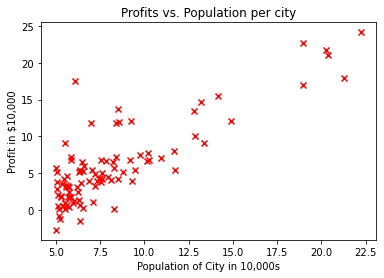

In [6]:
# 创建数据的散点图。若要把标记改成红色的 "x"，
# 我们使用了 'marker' 和 'c' 参数
plt.scatter(x_train, y_train, marker='x', c='r') 

# 设置标题
plt.title("Profits vs. Population per city")
# 设置 y 轴标签
plt.ylabel('Profit in $10,000')
# 设置 x 轴标签
plt.xlabel('Population of City in 10,000s')
plt.show()

你的目标是构建一个线性回归模型来拟合这些数据。
- 有了这个模型，你之后可以输入一个新城市的人口，让模型估计你的餐馆在该城市的潜在月利润。

<a name="4"></a>
## 4 - 线性回归回顾

在这个实践实验中，你将把线性回归参数 $(w,b)$ 拟合到你的数据集上。
- 线性回归的模型函数把 `x`（城市人口）映射到 `y`（你的餐馆在该城市的月利润），其表达式为
    $$f_{w,b}(x) = wx + b$$
    

- 要训练一个线性回归模型，你需要找到最能拟合数据集的 $(w,b)$ 参数。

    - 为了比较一个 $(w,b)$ 取值比另一个更好还是更差，你可以用代价函数 $J(w,b)$ 来评估它
      - $J$ 是 $(w,b)$ 的函数。也就是说，代价 $J(w,b)$ 的取值取决于 $(w,b)$ 的取值。
  
    - 最能拟合数据的 $(w,b)$ 取值，就是使代价 $J(w,b)$ 最小的那一个。


- 要找到使代价 $J(w,b)$ 尽可能小的 $(w,b)$ 取值，你可以使用一种称为**梯度下降**的方法。
  - 梯度下降每走一步，参数 $(w,b)$ 就更接近能达到最低代价 $J(w,b)$ 的最优值。
  

- 训练好的线性回归模型随后可以接收输入特征 $x$（城市人口），并输出预测 $f_{w,b}(x)$（该城市餐馆的预测月利润）。

<a name="5"></a>
## 5 - 计算代价

梯度下降包含反复调整参数 $(w,b)$ 取值的步骤，以逐步得到越来越小的代价 $J(w,b)$。
- 在梯度下降的每一步，计算代价 $J(w,b)$ 来监控 $(w,b)$ 更新过程中的进展会很有帮助。
- 本节中，你将实现一个计算 $J(w,b)$ 的函数，以便检查梯度下降实现的进展。

#### 代价函数
你可能还记得课上的内容：对于单变量情形，线性回归的代价函数 $J(w,b)$ 定义为

$$J(w,b) = \\frac{1}{2m} \\sum\\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2$$ 

- 你可以把 $f_{w,b}(x^{(i)})$ 看作模型对你餐馆利润的预测，而 $y^{(i)}$ 是数据中记录的实际利润。
- $m$ 是数据集中的训练样本数

#### 模型预测

- 对于单变量线性回归，模型 $f_{w,b}$ 对样本 $x^{(i)}$ 的预测表示为：

$$ f_{w,b}(x^{(i)}) = wx^{(i)} + b$$

这是直线的方程，截距为 $b$，斜率为 $w$

#### 实现

请完成下面的 `compute_cost()` 函数来计算代价 $J(w,b)$。

<a name="ex01"></a>
### 练习 1

完成下面的 `compute_cost`，使其能够：

* 遍历训练样本，对每个样本计算：
    * 模型对该样本的预测
    $$
    f_{wb}(x^{(i)}) =  wx^{(i)} + b 
    $$
   
    * 该样本的代价 $$cost^{(i)} =  (f_{wb} - y^{(i)})^2$$
    

* 返回所有样本的总代价
$$J(\\mathbf{w},b) = \\frac{1}{2m} \\sum\\limits_{i = 0}^{m-1} cost^{(i)}$$
  * 这里 $m$ 是训练样本数，$\\sum$ 是求和运算符

如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [9]:
# UNQ_C1
# 计分函数：compute_cost

def compute_cost(x, y, w, b): 
    """计算线性回归的代价函数。
   
    参数：
        x (ndarray): 形状 (m,)，模型的输入（城市人口）
        y (ndarray): 形状 (m,)，标签（城市的实际利润）
        w, b (scalar): 模型参数
   
    返回
        total_cost (float): 以 w、b 为线性回归参数来拟合 x 和 y 中数据点的代价"""
    # 训练样本数
    m = x.shape[0] 
    
    # 你需要正确返回这个变量
    total_cost = 0
    
    ### 在此处编写代码 ###

    ### 代码编写结束 ###

    return total_cost

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>


* 你可以用代码表示求和运算符，例如 $h = \\sum\\limits_{i = 0}^{m-1} 2i$：

```python 
h = 0
for i in range(m):
    h = h + 2*i
```


* 在这个例子中，你可以用 for 循环遍历 `x` 中的所有样本，并把每次迭代的 `cost` 累加到循环外初始化的变量（`cost_sum`）中。

* 然后，你可以返回 `total_cost`，即 `cost_sum` 除以 `2m`。

<details>
      <summary><font size="2" color="darkblue"><b> 点击查看更多提示</b></font></summary>

* 下面是这个函数整体实现的结构

```python 
def compute_cost(x, y, w, b):
    # number of training examples
    m = x.shape[0] 

    # You need to return this variable correctly
    total_cost = 0

    ### START CODE HERE ###  
    # Variable to keep track of sum of cost from each example
    cost_sum = 0

    # Loop over training examples
    for i in range(m):
        # Your code here to get the prediction f_wb for the ith example
        f_wb = 
        # Your code here to get the cost associated with the ith example
        cost = 

        # Add to sum of cost for each example
        cost_sum = cost_sum + cost 

    # Get the total cost as the sum divided by (2*m)
    total_cost = (1 / (2 * m)) * cost_sum
    ### END CODE HERE ### 

    return total_cost
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 `f_wb` 和 `cost`。

<details>
      <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
       &emsp; &emsp; 对于标量 $a$、$b$ 和 $c$（<code>x[i]</code>、<code>w</code> 和 <code>b</code> 都是标量），你可以在代码中把方程 $h = ab + c$ 写成 <code>h = a * b + c</code>
      <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f 的更多提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 f_wb：<code>f_wb = w * x[i] + b </code>
       </details>
</details>

 <details>
      <summary><font size="2" color="darkblue"><b>计算 cost 的提示</b></font></summary>
      &emsp; &emsp; 变量 z 的平方可以写成 z**2
      <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 cost 的更多提示</b></font></summary>
          &emsp; &emsp; 你可以这样计算 cost：<code>cost = (f_wb - y[i]) ** 2</code>
      </details>
</details>

</details>

</details>




你可以运行下面的测试代码，检查你的实现是否正确：

In [10]:
# 用参数 w、b 的某些初始值计算代价
initial_w = 2
initial_b = 1

cost = compute_cost(x_train, y_train, initial_w, initial_b)
print(type(cost))
print(f'Cost at initial w (zeros): {cost:.3f}')

# 公开测试
from public_tests import *
compute_cost_test(compute_cost)

<class 'numpy.float64'>
Cost at initial w (zeros): 75.203
All tests passed!


**预期输出**：
<table>
  <tr>
    <td> <b>初始 w（全零）时的代价：<b> 75.203 </td> 
  </tr>
</table>

<a name="6"></a>
## 6 - 梯度下降

本节中，你将实现线性回归参数 $w, b$ 的梯度。

正如讲课视频中所述，梯度下降算法为：

$$\\begin{align*}& \\text{repeat until convergence:} \\; \\lbrace \\newline \\; & \\phantom {0000} b := b -  \\alpha \\frac{\\partial J(w,b)}{\\partial b} \\newline       \\; & \\phantom {0000} w := w -  \\alpha \\frac{\\partial J(w,b)}{\\partial w} \\tag{1}  \\; & 
\\newline & \\rbrace\\end{align*}$$

其中参数 $w, b$ 是同时更新的，并且
$$
\\frac{\\partial J(w,b)}{\\partial b}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) \\tag{2}
$$
$$
\\frac{\\partial J(w,b)}{\\partial w}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) -y^{(i)})x^{(i)} \\tag{3}
$$
* m 是数据集中的训练样本数

    
*  $f_{w,b}(x^{(i)})$ 是模型的预测，而 $y^{(i)}$ 是目标值


你将实现一个名为 `compute_gradient` 的函数，用于计算 $\\frac{\\partial J(w)}{\\partial w}$、$\\frac{\\partial J(w)}{\\partial b}$

<a name="ex02"></a>
### 练习 2

请完成 `compute_gradient` 函数，使其能够：

* 遍历训练样本，对每个样本计算：
    * 模型对该样本的预测
    $$
    f_{wb}(x^{(i)}) =  wx^{(i)} + b 
    $$
   
    * 该样本对参数 $w, b$ 的梯度
        $$
        \\frac{\\partial J(w,b)}{\\partial b}^{(i)}  =  (f_{w,b}(x^{(i)}) - y^{(i)}) 
        $$
        $$
        \\frac{\\partial J(w,b)}{\\partial w}^{(i)}  =  (f_{w,b}(x^{(i)}) -y^{(i)})x^{(i)} 
        $$
    

* 返回所有样本的梯度更新总量
    $$
    \\frac{\\partial J(w,b)}{\\partial b}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} \\frac{\\partial J(w,b)}{\\partial b}^{(i)}
    $$
    
    $$
    \\frac{\\partial J(w,b)}{\\partial w}  = \\frac{1}{m} \\sum\\limits_{i = 0}^{m-1} \\frac{\\partial J(w,b)}{\\partial w}^{(i)} 
    $$
  * 这里 $m$ 是训练样本数，$\\sum$ 是求和运算符

如果卡住了，可以查看下方单元格给出的提示来帮助你完成实现。

In [ ]:
# UNQ_C2
# 计分函数：compute_gradient
def compute_gradient(x, y, w, b): 
    """计算线性回归的梯度
    参数：
      x (ndarray): 形状 (m,)，模型的输入（城市人口）
      y (ndarray): 形状 (m,)，标签（城市的实际利润）
      w, b (scalar): 模型参数
    返回
      dj_dw (scalar): 代价对参数 w 的梯度
      dj_db (scalar): 代价对参数 b 的梯度"""
    
    # 训练样本数
    m = x.shape[0]
    
    # 你需要正确返回以下变量
    dj_dw = 0
    dj_db = 0
    
    ### 在此处编写代码 ###
    
    ### 代码编写结束 ###
        
    return dj_dw, dj_db

<details>
<summary><font size="3" color="darkgreen"><b>点击查看提示</b></font></summary>

* 你可以用代码表示求和运算符，例如 $h = \\sum\\limits_{i = 0}^{m-1} 2i$：

```python 
h = 0
for i in range(m):
    h = h + 2*i
```


* 在这个例子中，你可以用 for 循环遍历 `x` 中的所有样本，并把每个样本的梯度累加到循环外初始化的变量 `dj_dw` 和 `dj_db` 中。

* 然后，你可以返回 `dj_dw` 和 `dj_db`，两者都除以 `m`。
<details>
      <summary><font size="2" color="darkblue"><b> 点击查看更多提示</b></font></summary>

* 下面是这个函数整体实现的结构

```python 
def compute_gradient(x, y, w, b): 
    """
    Computes the gradient for linear regression 
    Args:
      x (ndarray): Shape (m,) Input to the model (Population of cities) 
      y (ndarray): Shape (m,) Label (Actual profits for the cities)
      w, b (scalar): Parameters of the model  
    Returns
      dj_dw (scalar): The gradient of the cost w.r.t. the parameters w
      dj_db (scalar): The gradient of the cost w.r.t. the parameter b     
     """

    # Number of training examples
    m = x.shape[0]

    # You need to return the following variables correctly
    dj_dw = 0
    dj_db = 0

    ### START CODE HERE ### 
    # Loop over examples
    for i in range(m):  
        # Your code here to get prediction f_wb for the ith example
        f_wb = 

        # Your code here to get the gradient for w from the ith example 
        dj_dw_i = 

        # Your code here to get the gradient for b from the ith example 
        dj_db_i = 

        # Update dj_db : In Python, a += 1  is the same as a = a + 1
        dj_db += dj_db_i

        # Update dj_dw
        dj_dw += dj_dw_i

    # Divide both dj_dw and dj_db by m
    dj_dw = dj_dw / m
    dj_db = dj_db / m
    ### END CODE HERE ### 

    return dj_dw, dj_db
```


如果仍然卡住，可以查看下面的提示，弄清如何计算 `f_wb` 和 `cost`。

<details>
      <summary><font size="2" color="darkblue"><b>计算 f_wb 的提示</b></font></summary>
       &emsp; &emsp; 你在上一个练习中已经做过了！对于标量 $a$、$b$ 和 $c$（<code>x[i]</code>、<code>w</code> 和 <code>b</code> 都是标量），你可以在代码中把方程 $h = ab + c$ 写成 <code>h = a * b + c</code>
      <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f 的更多提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 f_wb：<code>f_wb = w * x[i] + b </code>
       </details>
</details>

<details>
      <summary><font size="2" color="darkblue"><b>计算 dj_dw_i 的提示</b></font></summary>
       &emsp; &emsp; 对于标量 $a$、$b$ 和 $c$（<code>f_wb</code>、<code>y[i]</code> 和 <code>x[i]</code> 都是标量），你可以在代码中把方程 $h = (a - b)c$ 写成 <code>h = (a-b)*c</code>
      <details>
          <summary><font size="2" color="blue"><b>&emsp; &emsp; 计算 f 的更多提示</b></font></summary>
           &emsp; &emsp; 你可以这样计算 dj_dw_i：<code>dj_dw_i = (f_wb - y[i]) * x[i] </code>
       </details>
</details>

<details>
      <summary><font size="2" color="darkblue"><b>计算 dj_db_i 的提示</b></font></summary>
         &emsp; &emsp; 你可以这样计算 dj_db_i：<code> dj_db_i = f_wb - y[i] </code>
</details>

</details>

</details>




运行下面的单元格，用两组不同的参数初始化 $w$、$b$ 来检查你对 `compute_gradient` 函数的实现。

In [ ]:
# 在 w 初始化为零的情况下计算并显示梯度
initial_w = 0
initial_b = 0

tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, initial_w, initial_b)
print('Gradient at initial w, b (zeros):', tmp_dj_dw, tmp_dj_db)

compute_gradient_test(compute_gradient)

现在，让我们在数据集上运行上面实现的梯度下降算法。

**预期输出**：
<table>
  <tr>
    <td> <b>初始 w, b（全零）处的梯度<b></td>
    <td> -65.32884975 -5.83913505154639</td> 
  </tr>
</table>

In [ ]:
# 在 w 非零的情况下计算并显示代价和梯度
test_w = 0.2
test_b = 0.2
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, test_w, test_b)

print('Gradient at test w, b:', tmp_dj_dw, tmp_dj_db)

**预期输出**：
<table>
  <tr>
    <td> <b>测试 w 处的梯度<b></td>
    <td> -47.41610118 -4.007175051546391</td> 
  </tr>
</table>

<a name="2.6"></a>
### 2.6 使用批量梯度下降学习参数

你现在将使用批量梯度下降来找到线性回归模型的最优参数。回忆一下，批量（batch）指的是在一次迭代中运行所有样本。
- 这一部分你不需要实现任何内容，只需运行下面的单元格。

- 验证梯度下降是否正确工作的一个好方法是查看 $J(w,b)$ 的值，检查它是否每一步都在减小。

- 假设你正确实现了梯度并正确计算了代价，且学习率 alpha 取值合适，那么 $J(w,b)$ 应该从不增大，并在算法结束时收敛到一个稳定值。

In [ ]:
def gradient_descent(x, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters): 
    """执行批量梯度下降以学习 theta。以学习率 alpha 走
    num_iters 个梯度步来更新 theta
   
    参数：
      x :    (ndarray): 形状 (m,)
      y :    (ndarray): 形状 (m,)
      w_in, b_in : (scalar) 模型参数的初始值
      cost_function: 用于计算代价的函数
      gradient_function: 用于计算梯度的函数
      alpha : (float) 学习率
      num_iters : (int) 运行梯度下降的迭代次数
    返回
      w : (ndarray): 形状 (1,) 运行梯度下降后更新得到的模型参数值
      b : (scalar)                运行梯度下降后更新得到的模型参数值"""
    
    # 训练样本数
    m = len(x)
    
    # 用于存放代价 J 和每次迭代的 w 的数组——主要供后续绘图使用
    J_history = []
    w_history = []
    w = copy.deepcopy(w_in)  # 避免在函数内修改全局变量 w
    b = b_in
    
    for i in range(num_iters):

        # 计算梯度并更新参数
        dj_dw, dj_db = gradient_function(x, y, w, b )  

        # 用 w、b、alpha 和梯度更新参数
        w = w - alpha * dj_dw               
        b = b - alpha * dj_db               

        # 每次迭代保存代价 J
        if i<100000:      # 防止资源耗尽
            cost =  cost_function(x, y, w, b)
            J_history.append(cost)

        # 每 10 次迭代打印一次代价；若迭代次数少于 10，则打印所有迭代
        if i% math.ceil(num_iters/10) == 0:
            w_history.append(w)
            print(f"Iteration {i:4}: Cost {float(J_history[-1]):8.2f}   ")
        
    return w, b, J_history, w_history #返回 w 以及用于绘图的 J、w 历史

现在，让我们运行上面的梯度下降算法来学习数据集对应的参数。

In [ ]:
# 初始化拟合参数。回忆一下，w 的形状是 (n,)
initial_w = 0.
initial_b = 0.

# 一些梯度下降设置
iterations = 1500
alpha = 0.01

w,b,_,_ = gradient_descent(x_train ,y_train, initial_w, initial_b, 
                     compute_cost, compute_gradient, alpha, iterations)
print("w,b found by gradient descent:", w, b)

**预期输出**：
<table>
  <tr>
    <td> <b>由梯度下降找到的 w, b<b></td>
    <td> 1.16636235 -3.63029143940436</td> 
  </tr>
</table>

我们现在将使用梯度下降得到的最终参数来绘制线性拟合。

回忆一下，我们可以得到单个样本的预测 $f(x^{(i)})= wx^{(i)}+b$。

要计算整个数据集上的预测，我们可以遍历所有训练样本，逐个计算每个样本的预测。下面的代码块展示了这一点。

In [ ]:
m = x_train.shape[0]
predicted = np.zeros(m)

for i in range(m):
    predicted[i] = w * x_train[i] + b

我们现在将绘制预测值，以查看线性拟合的效果。

In [ ]:
# 绘制线性拟合
plt.plot(x_train, predicted, c = "b")

# 创建数据的散点图。
plt.scatter(x_train, y_train, marker='x', c='r') 

# 设置标题
plt.title("Profits vs. Population per city")
# 设置 y 轴标签
plt.ylabel('Profit in $10,000')
# 设置 x 轴标签
plt.xlabel('Population of City in 10,000s')

你最终得到的 $w,b$ 取值也可以用来预测利润。让我们预测人口为 35,000 和 70,000 的地区利润会是多少。

- 模型以城市人口（单位为万）作为输入。

- 因此，35,000 人可以作为输入 `np.array([3.5])` 传给模型

- 类似地，70,000 人可以作为输入 `np.array([7.])` 传给模型


In [ ]:
predict1 = 3.5 * w + b
print('For population = 35,000, we predict a profit of $%.2f' % (predict1*10000))

predict2 = 7.0 * w + b
print('For population = 70,000, we predict a profit of $%.2f' % (predict2*10000))

**预期输出**：
<table>
  <tr>
    <td> <b> 人口 = 35,000 时，预测利润为<b></td>
    <td> $4519.77 </td> 
  </tr>
  
  <tr>
    <td> <b> 人口 = 70,000 时，预测利润为<b></td>
    <td> $45342.45 </td> 
  </tr>
</table>